In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv("../data/HR_Job_Placement_Dataset.csv")

In [3]:
def inspect_dataset(data):
    #Generate a summary of dataset structure and data quality.

    print("=" * 50)
    print("DATASET OVERVIEW")
    print("=" * 50)

    # Dataset dimensions
    rows, columns = data.shape
    print(f"Total records : {rows:,}")
    print(f"Total columns : {columns:,}")
    print(f"Duplicate rows: {data.duplicated().sum():,}")

    # Column information
    print("\n" + "=" * 50)
    print("COLUMN INFORMATION")
    print("=" * 50)
    data.info()

    # Missing-value analysis
    print("\n" + "=" * 50)
    print("MISSING VALUE SUMMARY")
    print("=" * 50)

    missing_summary = pd.DataFrame({
        "Missing_Count": data.isnull().sum(),
        "Missing_Percentage": (data.isnull().mean() * 100).round(2)
    })

    missing_summary = missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values("Missing_Percentage", ascending=False)

    if missing_summary.empty:
        print("No missing values found.")
    else:
        print(missing_summary)

    # Numeric and categorical columns
    print("\n" + "=" * 50)
    print("NUMERIC COLUMN SUMMARY")
    print("=" * 50) 
    print(data.describe().T)

    print("\n" + "=" * 50)
    print("CATEGORICAL COLUMN SUMMARY")
    print("=" * 50)

    categorical_columns = data.select_dtypes(
        include=["object", "category", "bool"]
    ).columns

    if len(categorical_columns) > 0:
        print(data[categorical_columns].describe().T)
    else:
        print("No categorical columns found.")

    # Target distribution
    target = "status"

    print("\n" + "=" * 50)
    print("TARGET DISTRIBUTION")
    print("=" * 50)

    if target in data.columns:
        print(data[target].value_counts(dropna=False))
        print("\nTarget percentage:")
        print(
            (data[target].value_counts(normalize=True, dropna=False) * 100)
            .round(2)
        )
    else:
        print(f"Target column '{target}' not found.")

    print("\nInspection completed.")


# Run the function
inspect_dataset(df)


DATASET OVERVIEW
Total records : 51,500
Total columns : 26
Duplicate rows: 1,376

COLUMN INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_exp

/var/folders/kn/d0lcr0v10y38q1c53h2w1y300000gn/T/ipykernel_5975/1664295089.py:49: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(


In [4]:
#Inspect categorical values and duplicate records.
def inspect_data_quality(data, max_unique=20):

    categorical_cols = data.select_dtypes(
        include=["object", "category", "str", "bool"]
    ).columns

    print("=" * 60)
    print("CATEGORICAL VALUE INSPECTION")
    print("=" * 60)

    for column in categorical_cols:
        print(f"\n{column} ({data[column].nunique(dropna=False)} unique values)")
        print(data[column].value_counts(dropna=False).head(max_unique))

    # Inspect duplicate records
    duplicate_rows = data[data.duplicated(keep=False)]

    print("\n" + "=" * 60)
    print("DUPLICATE RECORD INSPECTION")
    print("=" * 60)
    print(f"Rows involved in duplicates: {len(duplicate_rows):,}")

    if duplicate_rows.empty:
        print("No duplicate records found.")
    else:
        print("\nSample duplicate records:")
        print(duplicate_rows.head(10).to_string(index=False))

inspect_data_quality(df)


CATEGORICAL VALUE INSPECTION

gender (4 unique values)
gender
Female    24379
Male      24028
male       1549
female     1544
Name: count, dtype: int64

degree_specialization (5 unique values)
degree_specialization
Others                    10463
Electronics               10358
Information Technology    10298
Computer Science          10210
Mechanical                10171
Name: count, dtype: int64

internship_experience (4 unique values)
internship_experience
No      25607
Yes     23327
 no      1341
yes      1225
Name: count, dtype: int64

career_switch_willingness (3 unique values)
career_switch_willingness
Not Willing    28479
Willing        14555
NaN             8466
Name: count, dtype: int64

relevant_experience (3 unique values)
relevant_experience
Relevant        26305
Not Relevant    16769
NaN              8426
Name: count, dtype: int64

company_tier (6 unique values)
company_tier
Tier 1     19046
Tier 2     18301
Tier 3     12061
Tier 1       832
Tier 2       755
Tier 3       

In [5]:
#Standardize whitespace and capitalization in text columns.
def standardize_categories(data):

    cleaned_data = data.copy()

    text_columns = cleaned_data.select_dtypes(
        include=["object", "str", "category"]
    ).columns

    for column in text_columns:
        cleaned_data[column] = (
            cleaned_data[column]
            .str.strip()
        )

    # Standardize known categorical labels
    category_mappings = {
        "gender": {
            "male": "Male",
            "female": "Female"
        },
        "internship_experience": {
            "yes": "Yes",
            "no": "No"
        }
    }

    for column, mapping in category_mappings.items():
        if column in cleaned_data.columns:
            cleaned_data[column] = (
                cleaned_data[column]
                .replace(mapping)
            )

    return cleaned_data


# Standardize category formatting
df = standardize_categories(df)

# Recheck category counts
for column in ["gender", "internship_experience", "company_tier"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

# Investigate duplicate target consistency
duplicate_mask = df.duplicated(keep=False)
duplicate_records = df.loc[duplicate_mask]

print("\nDuplicate investigation:")
print("Duplicate rows involved:", len(duplicate_records))
print("\nTarget distribution among duplicate rows:")
print(duplicate_records["status"].value_counts(dropna=False))


gender:
gender
Female    25923
Male      25577
Name: count, dtype: int64

internship_experience:
internship_experience
No     26948
Yes    24552
Name: count, dtype: int64

company_tier:
company_tier
Tier 1    19878
Tier 2    19056
Tier 3    12566
Name: count, dtype: int64

Duplicate investigation:
Duplicate rows involved: 3000

Target distribution among duplicate rows:
status
Not Placed    2102
Placed         898
Name: count, dtype: int64


In [6]:
# Count exact duplicate rows after standardization
duplicate_count = df.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_count:,}")
print(f"Percentage of duplicate rows: {duplicate_count / len(df) * 100:.2f}%")

# Check whether identical feature records have conflicting targets
feature_columns = df.columns.drop("status")

target_conflicts = (
    df.groupby(list(feature_columns), dropna=False)["status"]
    .nunique()
)

conflicting_groups = target_conflicts[target_conflicts > 1]

print(f"\nFeature groups with conflicting targets: {len(conflicting_groups):,}")

# Show how many records belong to duplicate groups
duplicate_mask = df.duplicated(keep=False)

print(f"Rows involved in duplicate groups: {duplicate_mask.sum():,}")

Exact duplicate rows: 1,500
Percentage of duplicate rows: 2.91%

Feature groups with conflicting targets: 0
Rows involved in duplicate groups: 3,000


In [7]:
#Remove exact duplicate records and report the impact.
def remove_duplicate_rows(data):

    original_count = len(data)

    cleaned_data = data.drop_duplicates().copy()

    removed_count = original_count - len(cleaned_data)
    removed_percentage = removed_count / original_count * 100

    print(f"Original records       : {original_count:,}")
    print(f"Duplicate rows removed : {removed_count:,}")
    print(f"Remaining records      : {len(cleaned_data):,}")
    print(f"Removal percentage     : {removed_percentage:.2f}%")

    return cleaned_data


# Remove exact duplicates
df = remove_duplicate_rows(df)


Original records       : 51,500
Duplicate rows removed : 1,500
Remaining records      : 50,000
Removal percentage     : 2.91%


In [8]:
#Summarize missing values in each column.
def analyze_missing_values(data):

    missing_count = data.isnull().sum()

    missing_summary = pd.DataFrame({
        "Missing_Count": missing_count,
        "Missing_Percentage": (
            missing_count / len(data) * 100
        ).round(2)
    })

    # Display only columns that contain missing values
    missing_summary = missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values(
        by="Missing_Percentage",
        ascending=False
    )

    print(f"Total records: {len(data):,}")
    print(f"Columns with missing values: {len(missing_summary)}")

    return missing_summary


missing_summary = analyze_missing_values(df)
display(missing_summary)


Total records: 50,000
Columns with missing values: 9


,Missing_Count,Missing_Percentage
layoff_history,8234,16.47
career_switch_willingness,8224,16.45
relocation_willingness,8227,16.45
relevant_experience,8183,16.37
job_role_match,5949,11.90
ssc_percentage,2500,5.00
hsc_percentage,2000,4.00
notice_period_days,1532,3.06
employment_gap_months,1071,2.14


,count,mean,median,std,min,max,skewness
ssc_percentage,47500.0,70.02,69.98,7.98,50.0,95.0,0.05
hsc_percentage,48000.0,72.06,72.02,7.92,50.0,95.0,0.01
notice_period_days,48468.0,20.11,15.00,24.85,0.0,90.0,1.35
employment_gap_months,48929.0,3.06,0.00,4.43,0.0,18.0,1.72


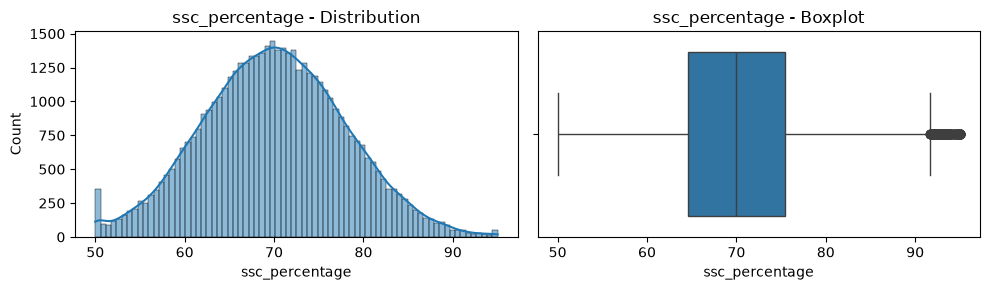

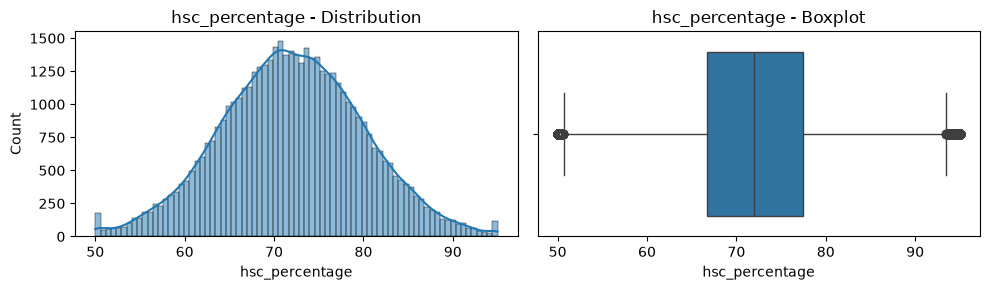

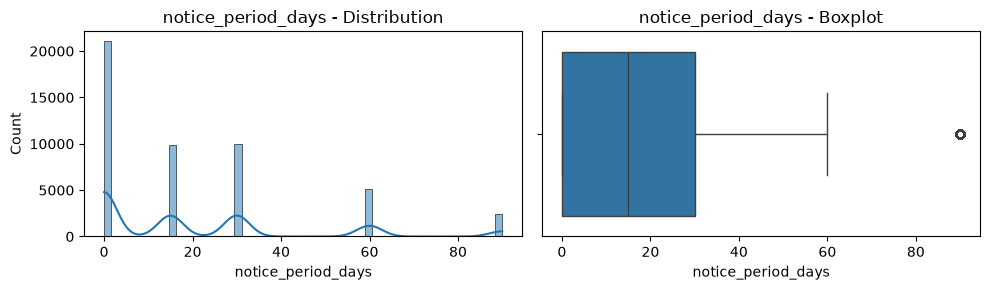

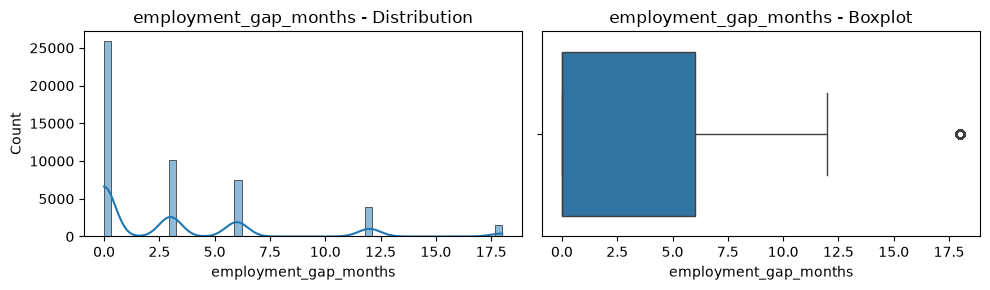

In [9]:
#Checking the distribution
numeric_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "notice_period_days",
    "employment_gap_months"
]

# Summary statistics and skewness
distribution_summary = df[numeric_columns].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

distribution_summary["skewness"] = (
    df[numeric_columns].skew()
)

display(distribution_summary.round(2))

# Plot histogram and boxplot for each column
for column in numeric_columns:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f"{column} - Distribution")

    sns.boxplot(
        data=df,
        x=column,
        ax=axes[1]
    )
    axes[1].set_title(f"{column} - Boxplot")

    plt.tight_layout()
    plt.show()

In [10]:
#Fill missing numeric values using each column's median.
def fill_numeric_missing_values(data, columns):

    cleaned_data = data.copy()

    for column in columns:
        median_value = cleaned_data[column].median()

        cleaned_data[column] = cleaned_data[column].fillna(
            median_value
        )

        print(f"{column}: missing values filled with {median_value:.2f}")

    return cleaned_data


numeric_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "notice_period_days",
    "employment_gap_months"
]

df = fill_numeric_missing_values(df, numeric_columns)

print("\nRemaining missing values in these columns:")
print(df[numeric_columns].isnull().sum())


ssc_percentage: missing values filled with 69.98
hsc_percentage: missing values filled with 72.02
notice_period_days: missing values filled with 15.00
employment_gap_months: missing values filled with 0.00

Remaining missing values in these columns:
ssc_percentage           0
hsc_percentage           0
notice_period_days       0
employment_gap_months    0
dtype: int64


In [11]:
#Fill missing categorical values with 'Unknown
def fill_categorical_missing_values(data, columns):

    cleaned_data = data.copy()

    for column in columns:
        missing_count = cleaned_data[column].isnull().sum()

        cleaned_data[column] = cleaned_data[column].fillna(
            "Unknown"
        )

        print(f"{column}: {missing_count:,} missing values filled")

    return cleaned_data


categorical_columns = [
    "layoff_history",
    "relocation_willingness",
    "career_switch_willingness",
    "relevant_experience",
    "job_role_match"
]

df = fill_categorical_missing_values(df, categorical_columns)


layoff_history: 8,234 missing values filled
relocation_willingness: 8,227 missing values filled
career_switch_willingness: 8,224 missing values filled
relevant_experience: 8,183 missing values filled
job_role_match: 5,949 missing values filled


In [12]:
df.isnull().sum()

age_years                    0
gender                       0
ssc_percentage               0
hsc_percentage               0
degree_percentage            0
degree_specialization        0
technical_score              0
aptitude_score               0
communication_score          0
skills_match_percentage      0
certifications_count         0
internship_experience        0
years_of_experience          0
career_switch_willingness    0
relevant_experience          0
previous_ctc_lpa             0
expected_ctc_lpa             0
company_tier                 0
job_role_match               0
competition_level            0
bond_requirement             0
notice_period_days           0
layoff_history               0
employment_gap_months        0
relocation_willingness       0
status                       0
dtype: int64

In [13]:
df.to_csv("../data/cleaned_job_placement_data.csv", index=False)
